# Task 2: Multi-class Classification on Fashion-MNIST with FCNN + Optimizer Comparison



In [27]:
import torch
import torch.nn as nn
import torch.optim as optim

import torchvision
import torchvision.transforms as transforms
from torch.utils.data import TensorDataset, DataLoader

import copy
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix

# Same random values every time
SEED = 42

torch.manual_seed(SEED)
np.random.seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device:", device)

Device: cuda


## 1. Load Fashion-MNIST

In [28]:
transform = transforms.ToTensor()

train_dataset = torchvision.datasets.FashionMNIST(
    root="./data",
    train=True,
    download=True,
    transform=transform
)

test_dataset = torchvision.datasets.FashionMNIST(
    root="./data",
    train=False,
    download=True,
    transform=transform
)

print("Official train samples:", len(train_dataset))
print("Official test samples:", len(test_dataset))

Official train samples: 60000
Official test samples: 10000


## 2. Select 5 classes and build the required 64/16/20 split


In [29]:
FASHION_MNIST_CLASSES = [
    "T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
    "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"
]

selected_classes = [1, 5, 7, 8, 9]
class_names = [FASHION_MNIST_CLASSES[c] for c in selected_classes]
print("Selected classes:", class_names)

X_all = np.concatenate([train_dataset.data.numpy(), test_dataset.data.numpy()], axis=0)
y_all = np.concatenate([train_dataset.targets.numpy(), test_dataset.targets.numpy()], axis=0)

mask = np.isin(y_all, selected_classes)
X = X_all[mask]
y = y_all[mask]

label_map = {old_label: new_label for new_label, old_label in enumerate(selected_classes)}
y = np.array([label_map[label] for label in y])

print("Total selected samples (5 classes, train+test merged):", len(X))
print("Classes present:", np.unique(y))

Selected classes: ['Trouser', 'Sandal', 'Sneaker', 'Bag', 'Ankle boot']
Total selected samples (5 classes, train+test merged): 35000
Classes present: [0 1 2 3 4]


In [30]:

X_trainval, X_test, y_trainval, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=SEED,
    stratify=y
)

X_train, X_val, y_train, y_val = train_test_split(
    X_trainval, y_trainval,
    test_size=0.20,
    random_state=SEED,
    stratify=y_trainval
)

n_total = len(X)
print(f"Train:      {len(X_train):6d}  ({100 * len(X_train) / n_total:.1f}% of total)")
print(f"Validation: {len(X_val):6d}  ({100 * len(X_val) / n_total:.1f}% of total)")
print(f"Test:       {len(X_test):6d}  ({100 * len(X_test) / n_total:.1f}% of total)")

Train:       22400  (64.0% of total)
Validation:   5600  (16.0% of total)
Test:         7000  (20.0% of total)


In [31]:

X_train = X_train.astype(np.float32) / 255.0
X_val   = X_val.astype(np.float32) / 255.0
X_test  = X_test.astype(np.float32) / 255.0

X_train = X_train.reshape(-1, 784)
X_val   = X_val.reshape(-1, 784)
X_test  = X_test.reshape(-1, 784)

# Convert NumPy arrays to PyTorch tensors
X_train = torch.tensor(X_train, dtype=torch.float32)
y_train = torch.tensor(y_train, dtype=torch.long)

X_val = torch.tensor(X_val, dtype=torch.float32)
y_val = torch.tensor(y_val, dtype=torch.long)

X_test = torch.tensor(X_test, dtype=torch.float32)
y_test = torch.tensor(y_test, dtype=torch.long)

print(X_train.shape, X_val.shape, X_test.shape)

torch.Size([22400, 784]) torch.Size([5600, 784]) torch.Size([7000, 784])


In [32]:
train_data = TensorDataset(X_train, y_train)
val_data   = TensorDataset(X_val, y_val)
test_data  = TensorDataset(X_test, y_test)

print("Train:", len(train_data))
print("Validation:", len(val_data))
print("Test:", len(test_data))

Train: 22400
Validation: 5600
Test: 7000


## 3. Model definition (FCNN)

In [52]:
class FCNN(nn.Module):

    def __init__(self, input_size, hidden_layers, output_size=5):
        super().__init__()

        layers = []

        # First hidden layer
        layers.append(nn.Linear(input_size, hidden_layers[0]))
        layers.append(nn.ReLU())

        # Remaining hidden layers
        for i in range(1, len(hidden_layers)):
            layers.append(
                nn.Linear(hidden_layers[i - 1], hidden_layers[i])
            )
            layers.append(nn.ReLU())

        # Output layer
        layers.append(nn.Linear(hidden_layers[-1], output_size))

        self.network = nn.Sequential(*layers)

    def forward(self, x):
        return self.network(x)

## 4. Architectures to compare


In [53]:
architectures = {
    "Arch-A (3 layers)": [128, 64, 32],
    "Arch-B (4 layers)": [256, 128, 64, 32],
    "Arch-C (5 layers)": [256, 128, 64, 32, 16]
    # "Arch-D (6 layers)": [256, 128, 64, 32, 16, 8],
    # "Arch-E (6 layers)": [512,256, 128, 64, 32, 16],
}

for name, layers in architectures.items():
    print(name, "->", layers)

Arch-A (3 layers) -> [128, 64, 32]
Arch-B (4 layers) -> [256, 128, 64, 32]
Arch-C (5 layers) -> [256, 128, 64, 32, 16]


## 5. Optimizers

In [54]:
def get_optimizer(model, name):
    lr = 0.001

    if name in ("SGD", "Batch GD"):
        return optim.SGD(model.parameters(), lr=lr)
    elif name == "Momentum":
        return optim.SGD(model.parameters(), lr=lr, momentum=0.9)
    elif name == "NAG":
        return optim.SGD(model.parameters(), lr=lr, momentum=0.9, nesterov=True)
    elif name == "RMSProp":
        return optim.RMSprop(model.parameters(), lr=lr, alpha=0.99, eps=1e-8)
    elif name == "Adam":
        return optim.Adam(model.parameters(), lr=lr, betas=(0.9, 0.999), eps=1e-8)
    else:
        raise ValueError(f"Unknown optimizer name: {name}")

## 6. Data loaders

In [55]:
val_loader = DataLoader(val_data, batch_size=256, shuffle=False)
test_loader = DataLoader(test_data, batch_size=256, shuffle=False)
eval_train_loader = DataLoader(train_data, batch_size=256, shuffle=False)  # for measuring train accuracy

## 8. Run the full experiment: every architecture x every optimizer


In [56]:
import os, copy
from google.colab import drive
from joblib import Parallel, delayed

drive.mount('/content/drive')
SAVE_DIR = "/content/drive/MyDrive/assg3_task2_results_final"   # NEW folder, old results would be skipped otherwise
os.makedirs(SAVE_DIR, exist_ok=True)

THRESHOLD = 1e-4
BATCH_SIZE = 16
MAX_EPOCHS = 100
BATCH_GD_MAX_EPOCHS = 5000


def arch_key(arch_name):
    return arch_name.split(" ")[0]


def safe_save(obj, path):
    tmp = path + ".tmp"
    torch.save(obj, tmp)
    os.replace(tmp, path)


def get_initial_state(arch_name):
    path = f"{SAVE_DIR}/init_{arch_key(arch_name)}.pt"
    if os.path.exists(path):
        return torch.load(path, weights_only=False)
    state = copy.deepcopy(FCNN(784, architectures[arch_name], 5).state_dict())
    safe_save(state, path)
    return state


def run_one(arch_name, hidden_layers, opt_name, initial_state,
            X_tr, y_tr, X_va, y_va, save_dir, threshold, seed, batch_size):
    torch.set_num_threads(1)
    torch.manual_seed(seed)

    key = f"{arch_key(arch_name)}_{opt_name.replace(' ', '')}"
    result_path = f"{save_dir}/result_{key}.pt"
    ckpt_path = f"{save_dir}/ckpt_{key}.pt"

    if os.path.exists(result_path):
        return f"{key}: already finished, skipped"

    model = FCNN(784, hidden_layers, 5)
    model.load_state_dict(initial_state)
    optimizer = get_optimizer(model, opt_name)
    criterion = nn.CrossEntropyLoss()

    is_batch_gd = (opt_name == "Batch GD")
    max_epochs = BATCH_GD_MAX_EPOCHS if is_batch_gd else MAX_EPOCHS
    n = len(X_tr)
    bs = n if is_batch_gd else batch_size

    errors, val_accs, start_epoch, stop_reason = [], [], 0, None

    if os.path.exists(ckpt_path):
        ck = torch.load(ckpt_path, weights_only=False)
        model.load_state_dict(ck["model"])
        optimizer.load_state_dict(ck["optimizer"])
        errors, val_accs = ck["errors"], ck["val_accs"]
        stop_reason = ck["stop_reason"]
        start_epoch = max_epochs if ck["done"] else ck["epoch"]

    def acc(X, y):
        model.eval()
        with torch.no_grad():
            preds = torch.cat([model(X[i:i+4096]).argmax(1) for i in range(0, len(X), 4096)])
        return 100 * (preds == y).float().mean().item()

    for epoch in range(start_epoch, max_epochs):
        model.train()
        perm = torch.randperm(n)
        Xs, ys = X_tr[perm], y_tr[perm]
        total = 0.0
        for i in range(0, n, bs):
            xb, yb = Xs[i:i+bs], ys[i:i+bs]
            loss = criterion(model(xb), yb)
            optimizer.zero_grad(set_to_none=True)
            loss.backward()
            optimizer.step()
            total += loss.item() * len(xb)

        errors.append(total / n)
        val_accs.append(acc(X_va, y_va))


        if len(errors) > 1 and abs(errors[-2] - errors[-1]) < threshold:
            stop_reason = "converged"
        elif epoch == max_epochs - 1:
            stop_reason = "max-epochs"
        done = stop_reason is not None

        if done or (epoch + 1) % 10 == 0:                  # checkpoint every 10 epochs (and at the end)
            safe_save({"model": model.state_dict(), "optimizer": optimizer.state_dict(),
                       "errors": errors, "val_accs": val_accs,
                       "epoch": epoch + 1, "done": done, "stop_reason": stop_reason}, ckpt_path)
        if done:
            break

    # final model = weights at the epoch where training stopped (no best-validation restore)
    safe_save({
        "epoch_errors": errors,
        "val_accuracies": val_accs,
        "epochs_to_converge": len(errors),
        "stop_reason": stop_reason,
        "train_accuracy": acc(X_tr, y_tr),
        "val_accuracy": acc(X_va, y_va),
        "state": copy.deepcopy(model.state_dict()),
    }, result_path)

    if os.path.exists(ckpt_path):
        os.remove(ckpt_path)
    return f"{key}: {stop_reason} after {len(errors)} epochs, val {acc(X_va, y_va):.2f}%"



def run_architecture(arch_name):
    init_state = get_initial_state(arch_name)
    n_jobs = min(len(optimizer_names), os.cpu_count())
    print(f"{arch_name}: running {len(optimizer_names)} optimizers on {n_jobs} cores")
    msgs = Parallel(n_jobs=n_jobs, verbose=10)(
        delayed(run_one)(arch_name, architectures[arch_name], o, init_state,
                         X_train, y_train, X_val, y_val,
                         SAVE_DIR, THRESHOLD, SEED, BATCH_SIZE)
        for o in optimizer_names
    )
    print("\n".join(msgs))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [57]:
run_architecture("Arch-A (3 layers)")

Arch-A (3 layers): running 6 optimizers on 2 cores


[Parallel(n_jobs=2)]: Using backend LokyBackend with 2 concurrent workers.
[Parallel(n_jobs=2)]: Done   1 tasks      | elapsed:    4.5s
[Parallel(n_jobs=2)]: Done   4 out of   6 | elapsed:  3.9min remaining:  1.9min


Arch-A_SGD: converged after 69 epochs, val 95.89%
Arch-A_BatchGD: converged after 2 epochs, val 20.00%
Arch-A_Momentum: converged after 30 epochs, val 96.89%
Arch-A_NAG: converged after 30 epochs, val 96.77%
Arch-A_RMSProp: converged after 49 epochs, val 97.18%
Arch-A_Adam: converged after 25 epochs, val 97.36%


[Parallel(n_jobs=2)]: Done   6 out of   6 | elapsed:  8.0min finished


In [58]:
run_architecture("Arch-B (4 layers)")

Arch-B (4 layers): running 6 optimizers on 2 cores


[Parallel(n_jobs=2)]: Using backend LokyBackend with 2 concurrent workers.
[Parallel(n_jobs=2)]: Done   1 tasks      | elapsed:    3.1s
[Parallel(n_jobs=2)]: Done   4 out of   6 | elapsed:  7.0min remaining:  3.5min


Arch-B_SGD: converged after 84 epochs, val 95.96%
Arch-B_BatchGD: converged after 2 epochs, val 20.00%
Arch-B_Momentum: converged after 45 epochs, val 97.11%
Arch-B_NAG: converged after 37 epochs, val 96.43%
Arch-B_RMSProp: converged after 33 epochs, val 97.21%
Arch-B_Adam: converged after 22 epochs, val 96.98%


[Parallel(n_jobs=2)]: Done   6 out of   6 | elapsed: 11.2min finished


In [59]:
run_architecture("Arch-C (5 layers)")

[Parallel(n_jobs=2)]: Using backend LokyBackend with 2 concurrent workers.


Arch-C (5 layers): running 6 optimizers on 2 cores


[Parallel(n_jobs=2)]: Done   1 tasks      | elapsed:    4.0s
[Parallel(n_jobs=2)]: Done   4 out of   6 | elapsed:  7.0min remaining:  3.5min


Arch-C_SGD: converged after 73 epochs, val 94.77%
Arch-C_BatchGD: converged after 2 epochs, val 20.00%
Arch-C_Momentum: converged after 27 epochs, val 96.82%
Arch-C_NAG: converged after 44 epochs, val 97.12%
Arch-C_RMSProp: converged after 64 epochs, val 96.82%
Arch-C_Adam: converged after 54 epochs, val 97.25%


[Parallel(n_jobs=2)]: Done   6 out of   6 | elapsed: 17.9min finished


In [60]:
# run_architecture("Arch-D (6 layers)")

In [61]:
# run_architecture("Arch-E (6 layers)")

In [62]:
results, trained_states, missing = {}, {}, []

for arch_name in architectures:
    results[arch_name], trained_states[arch_name] = {}, {}
    for opt_name in optimizer_names:
        path = f"{SAVE_DIR}/result_{arch_key(arch_name)}_{opt_name.replace(' ', '')}.pt"
        if not os.path.exists(path):
            missing.append((arch_name, opt_name))
            continue
        r = torch.load(path, weights_only=False)
        trained_states[arch_name][opt_name] = r.pop("state")
        results[arch_name][opt_name] = r

if missing:
    raise RuntimeError(f"These runs are not finished yet: {missing}")
print("All 18 runs loaded.")

All 18 runs loaded.


## 9. Results table: epochs to convergence, training and validation accuracy

In [63]:
rows = []
for arch_name in architectures:
    for opt_name in optimizer_names:
        r = results[arch_name][opt_name]
        rows.append({
              "Architecture": arch_name,
              "Optimizer": opt_name,
              "Epochs to Converge": r["epochs_to_converge"],
              "Stop reason": r["stop_reason"],
              "Train Accuracy (%)": round(r["train_accuracy"], 2),
              "Val Accuracy (%)": round(r["val_accuracy"], 2),
        })

results_df = pd.DataFrame(rows)
results_df

,Architecture,Optimizer,Epochs to Converge,Stop reason,Train Accuracy (%),Val Accuracy (%)
0,Arch-A (3 layers),SGD,69,converged,97.05,95.89
1,Arch-A (3 layers),Batch GD,2,converged,20.00,20.00
2,Arch-A (3 layers),Momentum,30,converged,98.99,96.89
3,Arch-A (3 layers),NAG,30,converged,98.80,96.77
4,Arch-A (3 layers),RMSProp,49,converged,99.71,97.18
5,Arch-A (3 layers),Adam,25,converged,99.46,97.36
6,Arch-B (4 layers),SGD,84,converged,97.75,95.96
7,Arch-B (4 layers),Batch GD,2,converged,20.00,20.00
8,Arch-B (4 layers),Momentum,45,converged,99.44,97.11
9,Arch-B (4 layers),NAG,37,converged,98.42,96.43


## 10. Training error vs. epoch, superimposed across optimizers (per architecture)

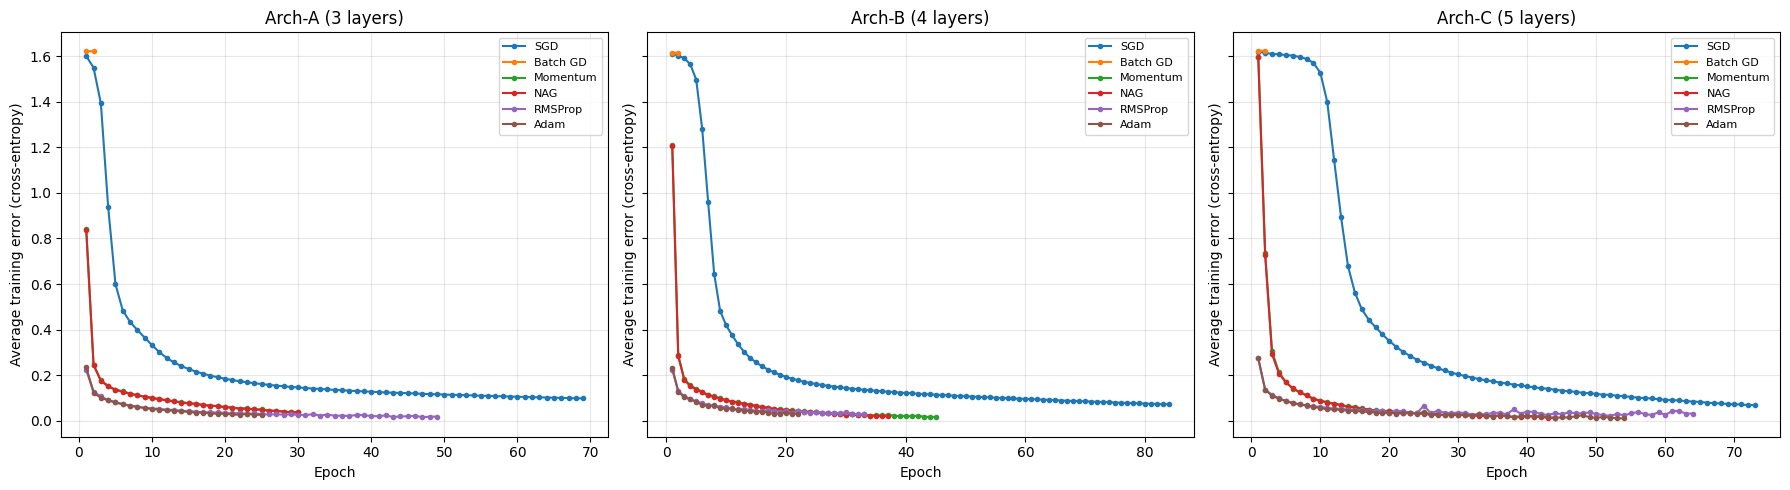

In [64]:
fig, axes = plt.subplots(1, len(architectures), figsize=(6 * len(architectures), 5), sharey=True)

if len(architectures) == 1:
    axes = [axes]

for ax, (arch_name, hidden_layers) in zip(axes, architectures.items()):
    for opt_name in optimizer_names:
        errors = results[arch_name][opt_name]["epoch_errors"]
        ax.plot(range(1, len(errors) + 1), errors, marker="o", markersize=3, label=opt_name)
    ax.set_title(arch_name)
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Average training error (cross-entropy)")
    ax.legend(fontsize=8)
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

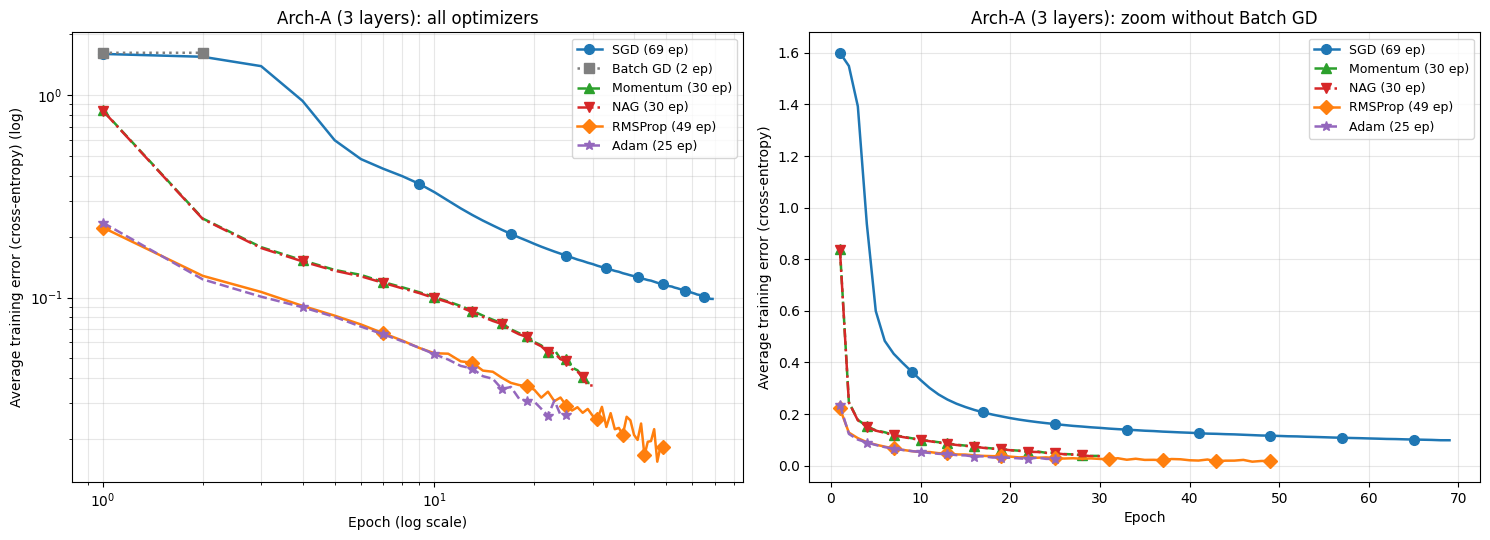

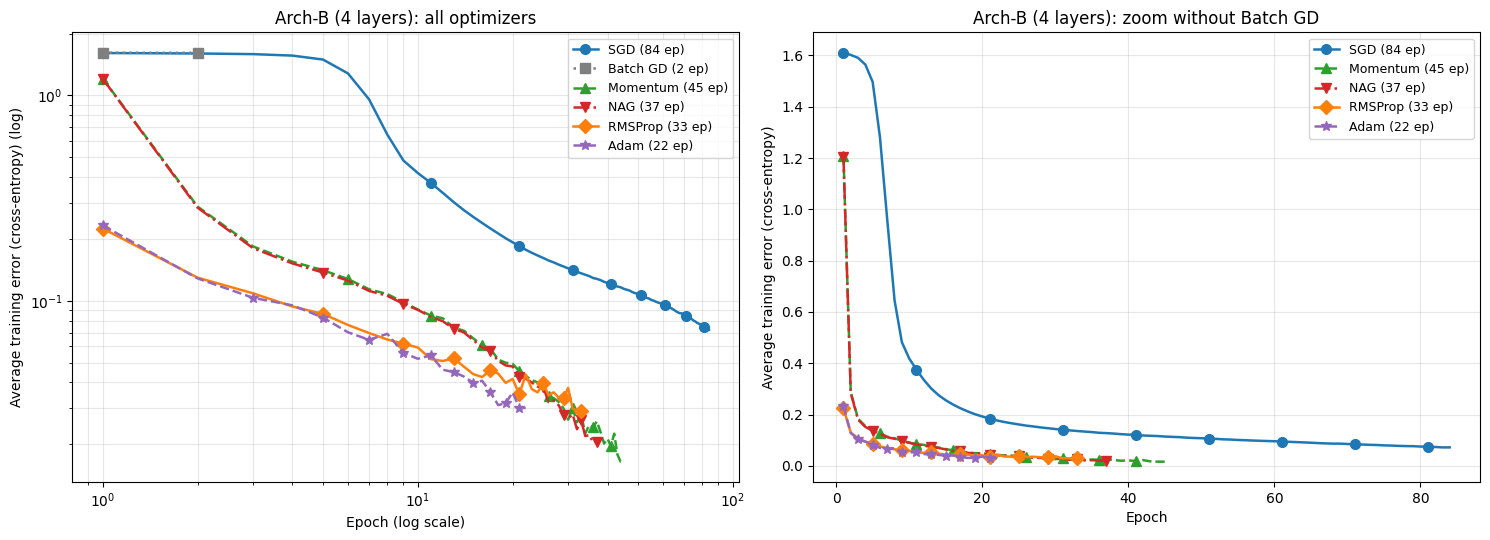

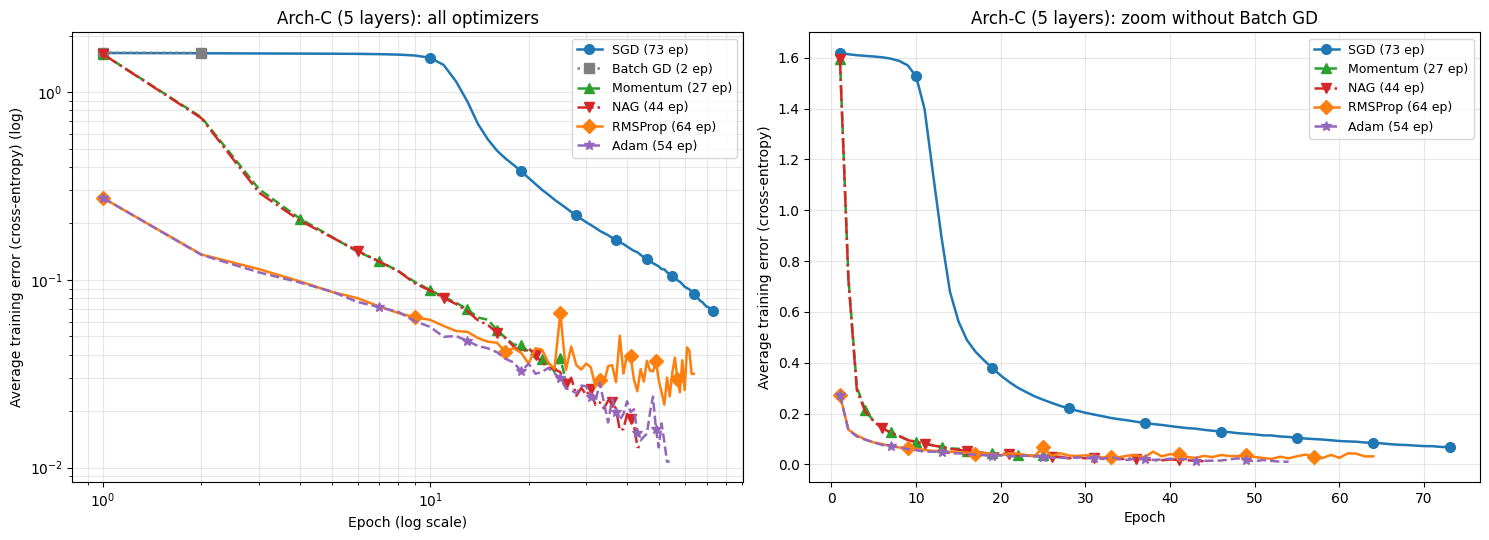

In [65]:
styles = {
    "SGD":      dict(color="#1f77b4", linestyle="-",  marker="o"),
    "Batch GD": dict(color="#7f7f7f", linestyle=":",  marker="s"),
    "Momentum": dict(color="#2ca02c", linestyle="--", marker="^"),
    "NAG":      dict(color="#d62728", linestyle="-.", marker="v"),
    "RMSProp":  dict(color="#ff7f0e", linestyle="-",  marker="D"),
    "Adam":     dict(color="#9467bd", linestyle="--", marker="*"),
}

def plot_curves(ax, arch_name, opts, log_x, log_y):
    for opt_name in opts:
        errors = results[arch_name][opt_name]["epoch_errors"]
        epochs = range(1, len(errors) + 1)
        ax.plot(epochs, errors,
                label=f"{opt_name} ({len(errors)} ep)",
                linewidth=1.8, markersize=7,
                markevery=max(1, len(errors) // 8),   # a few markers per curve, not one per point
                **styles[opt_name])
    if log_x: ax.set_xscale("log")
    if log_y: ax.set_yscale("log")
    ax.set_xlabel("Epoch" + (" (log scale)" if log_x else ""))
    ax.set_ylabel("Average training error (cross-entropy)" + (" (log)" if log_y else ""))
    ax.grid(alpha=0.3, which="both")
    ax.legend(fontsize=9)

for arch_name in architectures:
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5.5))

    plot_curves(ax1, arch_name, optimizer_names, log_x=True, log_y=True)
    ax1.set_title(f"{arch_name}: all optimizers")

    plot_curves(ax2, arch_name, [o for o in optimizer_names if o != "Batch GD"],
                log_x=False, log_y=False)
    ax2.set_title(f"{arch_name}: zoom without Batch GD")

    plt.tight_layout()
    plt.savefig(f"{SAVE_DIR}/error_curves_{arch_key(arch_name)}.png", dpi=150)
    plt.show()

## 11. Best architecture selection (by validation accuracy)



In [66]:
best_arch_name = None
best_opt_name = None
best_val_acc = -1.0

for arch_name in architectures:
    for opt_name in optimizer_names:
        val_acc = results[arch_name][opt_name]["val_accuracy"]
        if val_acc > best_val_acc:
            best_val_acc = val_acc
            best_arch_name = arch_name
            best_opt_name = opt_name

print(f"Best architecture: {best_arch_name}  ({architectures[best_arch_name]})")
print(f"Best optimizer for that architecture: {best_opt_name}")
print(f"Validation accuracy: {best_val_acc:.2f}%")

Best architecture: Arch-A (3 layers)  ([128, 64, 32])
Best optimizer for that architecture: Adam
Validation accuracy: 97.36%


## 12. Final evaluation of the chosen best architecture: accuracy and confusion matrices

In [67]:
best_model = FCNN(784, architectures[best_arch_name], 5).to(device)
best_model.load_state_dict(trained_states[best_arch_name][best_opt_name])
best_model.eval()


def get_predictions(model, data_loader):
    all_preds, all_labels = [], []
    with torch.no_grad():
        for X_batch, y_batch in data_loader:
            X_batch = X_batch.to(device)
            outputs = model(X_batch)
            preds = torch.argmax(outputs, dim=1).cpu().numpy()
            all_preds.extend(preds)
            all_labels.extend(y_batch.numpy())
    return np.array(all_labels), np.array(all_preds)


train_labels, train_preds = get_predictions(best_model, eval_train_loader)
test_labels, test_preds = get_predictions(best_model, test_loader)

train_accuracy = 100 * accuracy_score(train_labels, train_preds)
test_accuracy = 100 * accuracy_score(test_labels, test_preds)

train_cm = confusion_matrix(train_labels, train_preds)
test_cm = confusion_matrix(test_labels, test_preds)

print(f"Best model: {best_arch_name} + {best_opt_name}")
print(f"Training accuracy: {train_accuracy:.2f}%")
print(f"Test accuracy:     {test_accuracy:.2f}%")

Best model: Arch-A (3 layers) + Adam
Training accuracy: 99.46%
Test accuracy:     97.64%


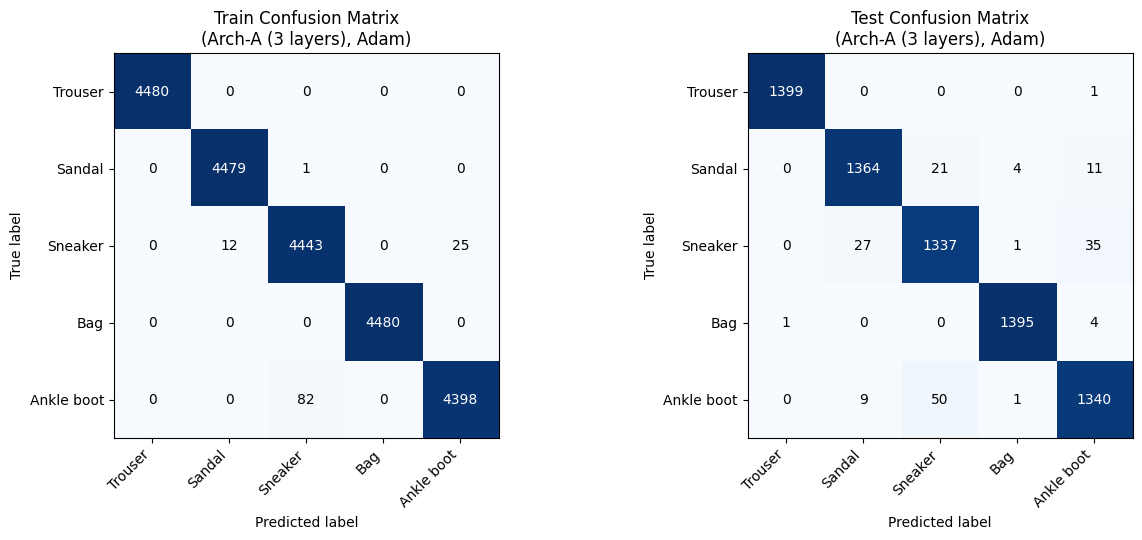

In [68]:
def plot_confusion_matrix(cm, class_names, title, ax):
    im = ax.imshow(cm, cmap="Blues")
    ax.set_title(title)
    ax.set_xlabel("Predicted label")
    ax.set_ylabel("True label")
    ax.set_xticks(range(len(class_names)))
    ax.set_yticks(range(len(class_names)))
    ax.set_xticklabels(class_names, rotation=45, ha="right")
    ax.set_yticklabels(class_names)

    thresh = cm.max() / 2
    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):
            ax.text(j, i, format(cm[i, j], "d"),
                     ha="center", va="center",
                     color="white" if cm[i, j] > thresh else "black")
    return im


fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
plot_confusion_matrix(train_cm, class_names, f"Train Confusion Matrix\n({best_arch_name}, {best_opt_name})", axes[0])
plot_confusion_matrix(test_cm, class_names, f"Test Confusion Matrix\n({best_arch_name}, {best_opt_name})", axes[1])
plt.tight_layout()
plt.show()